In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("creditcard.csv")

print("Shape:", df.shape)
df.head()

Shape: (284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     284807 non-nu

In [3]:
df['Class'].value_counts()

Class
0    284315
1       492
Name: count, dtype: int64

In [4]:
print("Duplicate rows:", df.duplicated().sum())

print(df['Amount'].describe())

Duplicate rows: 1081
count    284807.000000
mean         88.349619
std         250.120109
min           0.000000
25%           5.600000
50%          22.000000
75%          77.165000
max       25691.160000
Name: Amount, dtype: float64


In [5]:
df_clean = df.drop_duplicates()
print("Original shape:", df.shape)
print("Clean shape:", df_clean.shape)

print(df_clean['Class'].value_counts())

Original shape: (284807, 31)
Clean shape: (283726, 31)
Class
0    283253
1       473
Name: count, dtype: int64


In [6]:
fraud = df_clean[df_clean['Class'] == 1]
normal = df_clean[df_clean['Class'] == 0]

print("Fraud transactions - Amount summary:")
print(fraud['Amount'].describe())
print()
print("Normal transactions - Amount summary:")
print(normal['Amount'].describe())

Fraud transactions - Amount summary:
count     473.000000
mean      123.871860
std       260.211041
min         0.000000
25%         1.000000
50%         9.820000
75%       105.890000
max      2125.870000
Name: Amount, dtype: float64

Normal transactions - Amount summary:
count    283253.000000
mean         88.413575
std         250.379023
min           0.000000
25%           5.670000
50%          22.000000
75%          77.460000
max       25691.160000
Name: Amount, dtype: float64


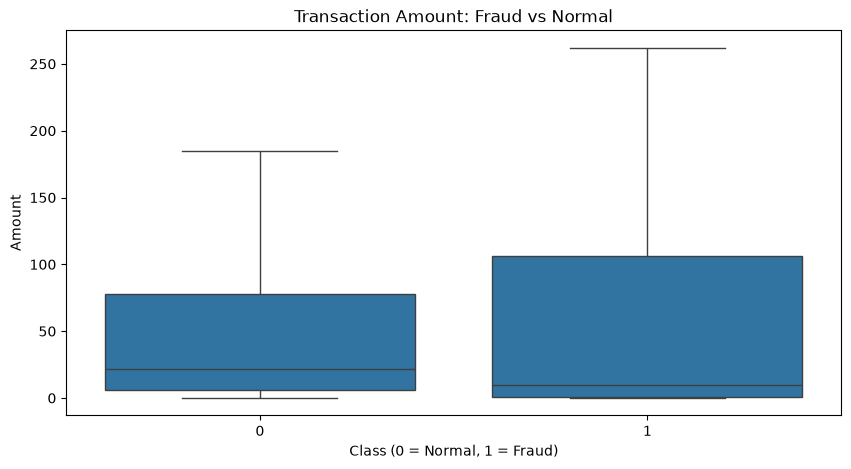

In [7]:
plt.figure(figsize=(10,5))
sns.boxplot(x='Class', y='Amount', data=df_clean, showfliers=False)
plt.title('Transaction Amount: Fraud vs Normal')
plt.xlabel('Class (0 = Normal, 1 = Fraud)')
plt.ylabel('Amount')
plt.show()

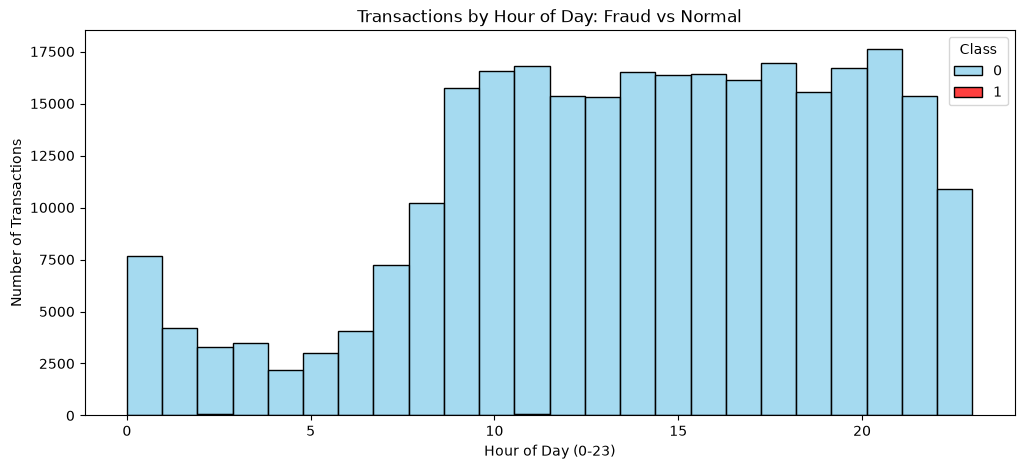

In [8]:
df_clean = df_clean.copy()
df_clean['Hour'] = (df_clean['Time'] // 3600) % 24

plt.figure(figsize=(12,5))
sns.histplot(data=df_clean, x='Hour', hue='Class', bins=24, multiple='stack', palette=['skyblue', 'red'])
plt.title('Transactions by Hour of Day: Fraud vs Normal')
plt.xlabel('Hour of Day (0-23)')
plt.ylabel('Number of Transactions')
plt.show()

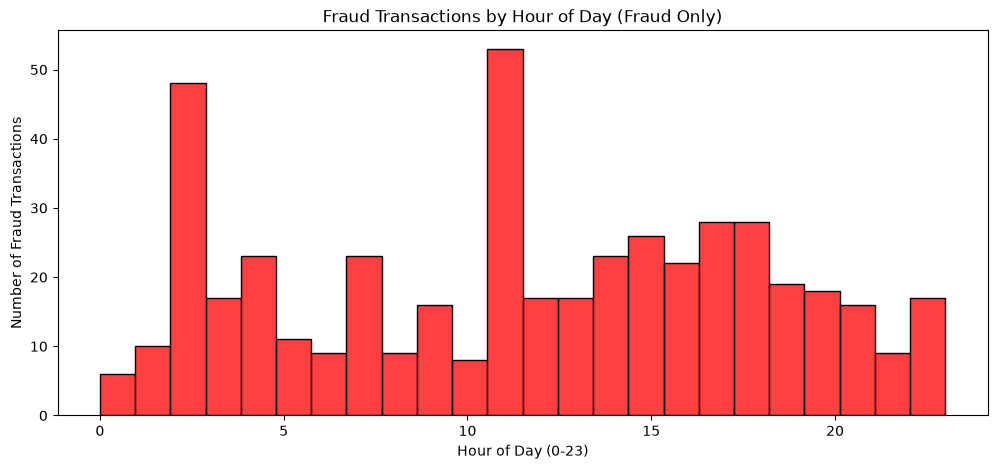

In [11]:
fraud = df_clean[df_clean['Class'] == 1]
normal = df_clean[df_clean['Class'] == 0]

plt.figure(figsize=(12,5))
sns.histplot(data=fraud, x='Hour', bins=24, color='red')
plt.title('Fraud Transactions by Hour of Day (Fraud Only)')
plt.xlabel('Hour of Day (0-23)')
plt.ylabel('Number of Fraud Transactions')
plt.show()

In [12]:
from sklearn.preprocessing import StandardScaler

features = df_clean.drop(columns=['Time', 'Class', 'Hour'])

scaler = StandardScaler()
features_scaled = features.copy()
features_scaled['Amount'] = scaler.fit_transform(features[['Amount']])

print(features_scaled.shape)
features_scaled.head()

(283726, 29)


,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,...,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount
0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,0.090794,...,0.251412,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,0.244200
1,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,-0.166974,...,-0.069083,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,-0.342584
2,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,0.207643,...,0.524980,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,1.158900
3,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,-0.054952,...,-0.208038,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,0.139886
4,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,0.753074,...,0.408542,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,-0.073813


In [13]:
from sklearn.ensemble import IsolationForest

model = IsolationForest(n_estimators=100, contamination=0.0017, random_state=42)

model.fit(features_scaled)

predictions = model.predict(features_scaled)

df_clean['Predicted_Fraud'] = (predictions == -1).astype(int)

print(df_clean['Predicted_Fraud'].value_counts())

Predicted_Fraud
0    283243
1       483
Name: count, dtype: int64


In [14]:
from sklearn.metrics import confusion_matrix, classification_report

print(confusion_matrix(df_clean['Class'], df_clean['Predicted_Fraud']))
print()
print(classification_report(df_clean['Class'], df_clean['Predicted_Fraud']))

[[282885    368]
 [   358    115]]

              precision    recall  f1-score   support

           0       1.00      1.00      1.00    283253
           1       0.24      0.24      0.24       473

    accuracy                           1.00    283726
   macro avg       0.62      0.62      0.62    283726
weighted avg       1.00      1.00      1.00    283726



In [15]:
model2 = IsolationForest(n_estimators=100, contamination=0.01, random_state=42)
model2.fit(features_scaled)
predictions2 = model2.predict(features_scaled)
df_clean['Predicted_Fraud_v2'] = (predictions2 == -1).astype(int)

print(confusion_matrix(df_clean['Class'], df_clean['Predicted_Fraud_v2']))
print()
print(classification_report(df_clean['Class'], df_clean['Predicted_Fraud_v2']))

[[280664   2589]
 [   224    249]]

              precision    recall  f1-score   support

           0       1.00      0.99      1.00    283253
           1       0.09      0.53      0.15       473

    accuracy                           0.99    283726
   macro avg       0.54      0.76      0.57    283726
weighted avg       1.00      0.99      0.99    283726



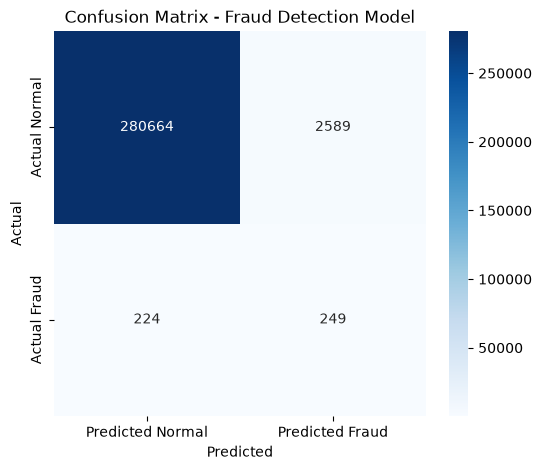

In [16]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(df_clean['Class'], df_clean['Predicted_Fraud_v2'])

plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['Predicted Normal', 'Predicted Fraud'],
            yticklabels=['Actual Normal', 'Actual Fraud'])
plt.title('Confusion Matrix - Fraud Detection Model')
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.show()

In [17]:
from sklearn.neighbors import LocalOutlierFactor

lof = LocalOutlierFactor(n_neighbors=20, contamination=0.01)

predictions_lof = lof.fit_predict(features_scaled)

df_clean['Predicted_Fraud_LOF'] = (predictions_lof == -1).astype(int)

print(confusion_matrix(df_clean['Class'], df_clean['Predicted_Fraud_LOF']))
print()
print(classification_report(df_clean['Class'], df_clean['Predicted_Fraud_LOF']))

[[280418   2835]
 [   470      3]]

              precision    recall  f1-score   support

           0       1.00      0.99      0.99    283253
           1       0.00      0.01      0.00       473

    accuracy                           0.99    283726
   macro avg       0.50      0.50      0.50    283726
weighted avg       1.00      0.99      0.99    283726



C:\ProgramData\anaconda3\Lib\site-packages\sklearn\neighbors\_lof.py:327: UserWarning: Duplicate values are leading to incorrect results. Increase the number of neighbors for more accurate results.
  warnings.warn(


## Key Findings & Insights

### 1. Severe Class Imbalance
Out of 283,726 clean transactions, only 473 (0.17%) were fraudulent. This extreme imbalance 
means standard accuracy is a misleading metric — a model predicting "no fraud" for every 
transaction would still be 99.83% "accurate" while catching zero fraud cases. Recall 
(the % of actual fraud correctly identified) is a far more meaningful metric here.

### 2. Transaction Amount Pattern
The median transaction amount for fraud cases (£9.82) is notably lower than for normal 
transactions (£22.00), despite a higher average (£123.87 vs £88.41) driven by a few large 
outliers. This is consistent with a known fraud tactic — "card testing" — where fraudsters 
make small transactions first to verify a stolen card is active before attempting larger charges.

### 3. Time-of-Day Pattern
Fraudulent transactions spike disproportionately during low-activity night hours (especially 
around 2–3 AM), when genuine transaction volume is at its lowest. This suggests fraud detection 
systems should apply heightened scrutiny during overnight hours, when customers are least 
likely to notice unauthorized activity in real time.

### 4. Anomaly Detection Model Comparison
Two unsupervised anomaly detection algorithms were built and compared, without using the 
Class label during training:

| Model | Recall | Precision |
|---|---|---|
| Isolation Forest (contamination=0.01) | 53% | 9% |
| Local Outlier Factor (n_neighbors=20) | 1% | ~0% |

**Isolation Forest significantly outperformed LOF**, correctly flagging 249 of 473 fraud cases 
vs. just 3 for LOF. This suggests a global, isolation-based approach is better suited to this 
high-dimensional, PCA-transformed dataset than a local neighborhood-based approach.

### 5. Precision-Recall Trade-off
Increasing the contamination parameter from 0.17% to 1% raised recall from 24% to 53%, but 
dropped precision from 24% to 9% (more false alarms). This reflects a core business trade-off 
in fraud detection: prioritizing recall (catching more fraud) typically increases false positives 
(flagging genuine customers), while prioritizing precision reduces customer friction but risks 
missing real fraud. Most financial institutions lean toward higher recall, since a missed fraud 
case is typically costlier than a false alarm.

### Recommendation
Deploy the Isolation Forest model (contamination ≈ 1%) as a first-pass flagging system, paired 
with manual or secondary review for flagged transactions to reduce false-positive impact on 
genuine customers. Apply additional scrutiny to small-value transactions and those occurring 
during overnight hours (12 AM–4 AM).

In [18]:
df_clean.to_csv("fraud_analysis_results.csv", index=False)

fraud.to_csv("fraud_only_transactions.csv", index=False)

model_comparison = pd.DataFrame({
    'Model': ['Isolation Forest', 'Local Outlier Factor'],
    'Recall_%': [53, 1],
    'Precision_%': [9, 0],
    'Fraud_Caught': [249, 3],
    'Total_Fraud': [473, 473]
})
model_comparison.to_csv("model_comparison.csv", index=False)

print("Files saved successfully")

Files saved successfully
